# Beginner findings 18-22: stars

Section E was not explored step by step in its own notebook, so the numbers each finding needs are computed here
straight from the Gaia file and saved to `numbers/BF18...csv` to `numbers/BF22...csv`, with a chart for each finding.
Star names (Pleiades, Barnard's Star ...) are matched by position to known catalogue positions: outside knowledge.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib.ticker import FuncFormatter
from sklearn.cluster import DBSCAN

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
st = hp.read_csv("stars", usecols=["source_id", "ra", "dec", "l", "b", "distance_pc", "pmra", "pmdec", "radial_velocity",
                                   "phot_g_mean_mag", "bp_rp", "abs_g_mag", "ruwe"])
N = len(st)
has_col = st["bp_rp"].notna() & st["abs_g_mag"].notna()
wd = has_col & (st["abs_g_mag"] > 10 + 2.6 * st["bp_rp"]) & (st["bp_rp"] < 1.7)
giant = has_col & (st["abs_g_mag"] < 3.5) & (st["bp_rp"] > 0.9)
ms = has_col & ~wd & ~giant
KNOWN = {  # J2000 positions (degrees): outside knowledge, used only to put names on rows
    "Proxima Centauri": (217.429, -62.680), "Barnard's Star": (269.452, 4.693), "Groombridge 1830": (178.245, 37.719),
    "Kapteyn's Star": (77.919, -45.018), "Pleiades (centre)": (56.75, 24.12)}


def nearest_to(ra0, dec0, within_deg=0.2):
    dd = np.hypot((st["ra"] - ra0) * np.cos(np.radians(dec0)), st["dec"] - dec0)
    i = dd.idxmin()
    return (st.loc[i], float(dd[i])) if dd[i] <= within_deg else (None, float(dd[i]))


print(f"{N:,} stars; with colour {int(has_col.sum()):,}")

1,165,165 stars; with colour 1,114,566


## Finding 18: colour against true brightness sorts stars into families

             key         value      shown         unit                                  source
0           rows  1.165165e+06  1,165,165                                             our data
1    with_colour  1.114566e+06  1,114,566                                             our data
2             wd  8.459500e+04     84,595                                             our data
3       wd_clean  5.599500e+04     55,995                                             our data
4         giants  5.058000e+03      5,058                                             our data
5       main_seq  1.024913e+06  1,024,913                                             our data
6           wd_a  1.000000e+01         10                                         rule we used
7           wd_b  2.600000e+00        2.6                                         rule we used
8      wd_colour  1.700000e+00        1.7                                         rule we used
9      giant_mag  3.500000e+00        3.5         

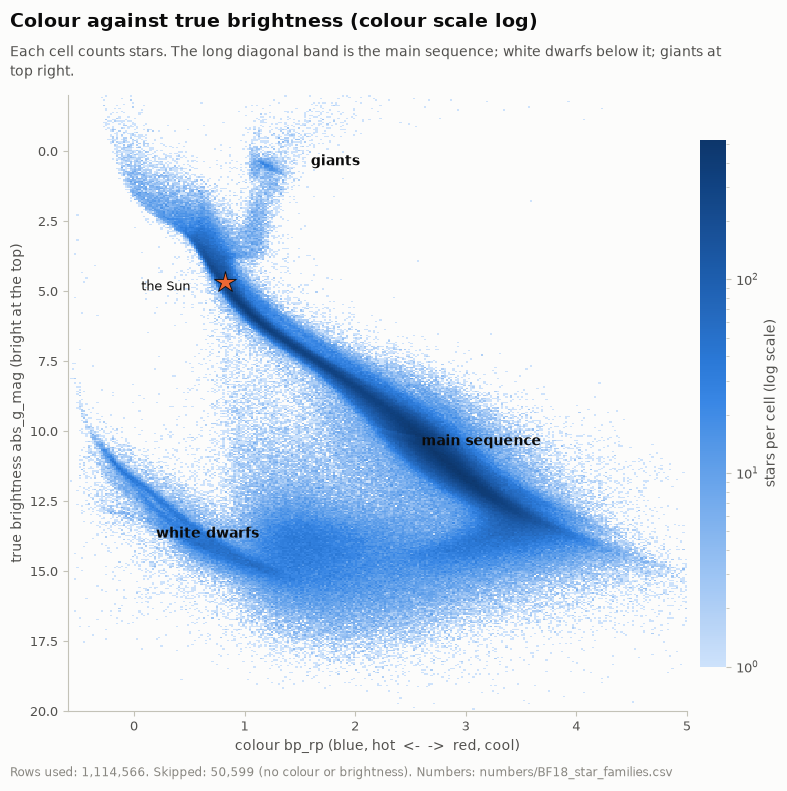

In [2]:
F = Facts(18, "star_families")
F.add("rows", N); F.add("with_colour", int(has_col.sum()))
F.add("wd", int(wd.sum())); F.add("wd_clean", int((wd & (st["ruwe"] < 1.4)).sum())); F.add("giants", int(giant.sum()))
F.add("main_seq", int(ms.sum()))
F.rule("wd_a", 10, "10"); F.rule("wd_b", 2.6, "2.6"); F.rule("wd_colour", 1.7, "1.7"); F.rule("giant_mag", 3.5, "3.5"); F.rule("giant_colour", 0.9, "0.9")
F.rule("ruwe_cut", 1.4, "1.4")
F.outside("sun_bp_rp", 0.82, "0.82", source="the brief (the Sun's colour)"); F.outside("sun_absg", 4.67, "4.67", source="the brief (the Sun's true brightness)")
px, dx = nearest_to(*KNOWN["Proxima Centauri"])
F.add("prox_bp_rp", px["bp_rp"], d(px["bp_rp"], 2)); F.add("prox_absg", px["abs_g_mag"], d(px["abs_g_mag"], 2)); F.add("prox_dist", px["distance_pc"], d(px["distance_pc"], 2), "pc")
F.outside("pc_ly", 3.26, "3.26", "light-years", source="README (1 parsec)")
F.add("prox_ly", px["distance_pc"] * 3.26, d(px["distance_pc"] * 3.26, 2), "light-years")
print(F.table().to_string()); f18 = F.save()
xe, ye = np.arange(-0.6, 5.01, 0.02), np.arange(-2, 20.01, 0.05)
H2, _, _ = np.histogram2d(st.loc[has_col, "bp_rp"], st.loc[has_col, "abs_g_mag"], bins=[xe, ye])
cm = hp.seq_cmap(start_at_surface=False); cm.set_bad(hp.SURFACE)
fig, ax = plt.subplots(figsize=(8.5, 8))
im = ax.pcolormesh(xe, ye, np.ma.masked_equal(H2.T, 0), cmap=cm, norm=LogNorm(vmin=1, vmax=H2.max()), rasterized=True)
ax.invert_yaxis(); ax.grid(False)
ax.plot(0.82, 4.67, marker="*", ms=16, color=hp.SERIES[1], mec=hp.INK, mew=0.6)
ax.annotate("the Sun", (0.82, 4.67), xytext=(-60, -6), textcoords="offset points", fontsize=9.5, color=hp.INK)
for lab, (x_, y_) in {"main sequence": (2.6, 10.5), "white dwarfs": (0.2, 13.8), "giants": (1.6, 0.5)}.items():
    ax.text(x_, y_, lab, fontsize=10, color=hp.INK, weight="bold")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.set_label("stars per cell (log scale)"); cb.outline.set_visible(False)
ax.set_xlabel("colour bp_rp (blue, hot  <-  ->  red, cool)"); ax.set_ylabel("true brightness abs_g_mag (bright at the top)")
hp.add_titles(fig, "Colour against true brightness (colour scale log)",
              "Each cell counts stars. The long diagonal band is the main sequence; white dwarfs below it; giants at top right.",
              hp.caption(int(has_col.sum()), N - int(has_col.sum()), "no colour or brightness", "numbers/BF18_star_families.csv"))
c18 = hp.save_chart(fig, "BF18_colour_brightness"); plt.show()
hp.log_entry("E-BF18", "Beginner finding 18 chart: colour against true brightness", step=6, chart=c18, numbers=f18,
             rows_used=int(has_col.sum()), rows_skipped=f"{N - int(has_col.sum()):,} (no colour)",
             key_numbers=[f"white-dwarf-like {int(wd.sum()):,} ({int((wd & (st['ruwe'] < 1.4)).sum()):,} clean); giant-like {int(giant.sum()):,}"],
             what_it_shows="Stars fall into a few bands: the main sequence, the white dwarfs below it, and a few giants above.")

## Finding 19: three out of four nearby stars are red dwarfs

        key         value      shown unit                                              source
0   ms_rows  1.024913e+06  1,024,913                                                 our data
1      n_OB  6.680000e+02        668                                                 our data
2    pct_OB  6.517626e-02      0.07%                                                 our data
3       n_A  3.135000e+03      3,135                                                 our data
4     pct_A  3.058796e-01      0.31%                                                 our data
5       n_F  3.205400e+04     32,054                                                 our data
6     pct_F  3.127485e+00       3.1%                                                 our data
7       n_G  5.196200e+04     51,962                                                 our data
8     pct_G  5.069894e+00       5.1%                                                 our data
9       n_K  1.445230e+05    144,523                        

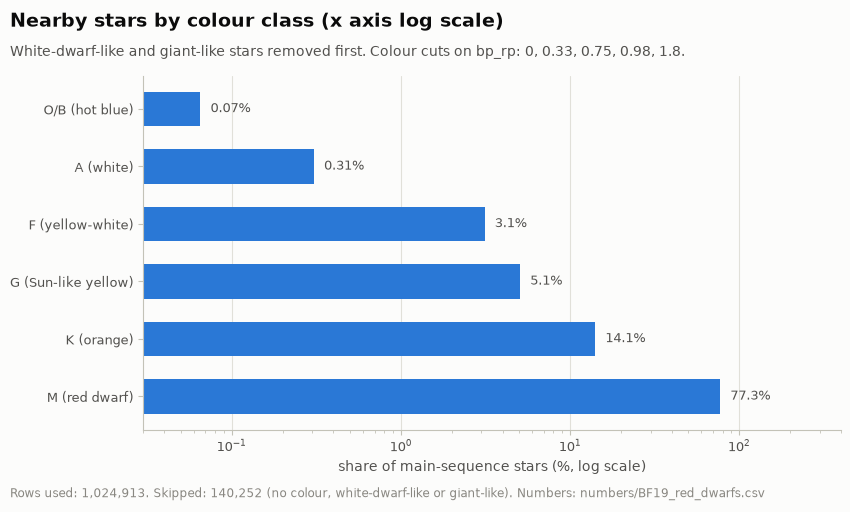

In [3]:
F = Facts(19, "red_dwarfs")
cuts = [-np.inf, 0, 0.33, 0.75, 0.98, 1.8, np.inf]
names = ["O/B", "A", "F", "G", "K", "M"]
cls = pd.cut(st.loc[ms, "bp_rp"], cuts, labels=names, right=False).value_counts().reindex(names)
F.add("ms_rows", int(ms.sum()))
for nm in names:
    k_ = nm.replace("/", "")
    F.add(f"n_{k_}", int(cls[nm])); F.add(f"pct_{k_}", 100 * cls[nm] / cls.sum(), p(100 * cls[nm] / cls.sum(), 1 if cls[nm] / cls.sum() > 0.01 else 2))
for k_, c_ in zip(["c1", "c2", "c3", "c4", "c5"], [0, 0.33, 0.75, 0.98, 1.8]):
    F.rule(k_, c_, d(c_, 2) if c_ not in (0,) else "0")
F.add("m_per_4", 4 * cls["M"] / cls.sum(), d(4 * cls["M"] / cls.sum(), 1))
# out of 100 stars (largest-remainder rounding, so the boxes add up to exactly 100)
raw100 = 100 * cls / cls.sum(); w100 = np.floor(raw100).astype(int)
for nm_ in (raw100 - w100).sort_values(ascending=False).index[:100 - int(w100.sum())]:
    w100[nm_] += 1
for nm in names:
    F.add(f"w_{nm.replace('/', '')}", int(w100[nm]), source="our data (out of 100, rounded so the total is 100)")
F.rule("hundred", 100, "100")
print(F.table().to_string()); f19 = F.save()
fig, ax = plt.subplots(figsize=(9, 4.6))
yy = np.arange(len(names))[::-1]
ax.barh(yy, (100 * cls / cls.sum()).values, height=0.6, color=hp.SERIES[0])
for y_, v_ in zip(yy, (100 * cls / cls.sum()).values):
    ax.text(v_ * 1.15, y_, f"{v_:.2f}%" if v_ < 1 else f"{v_:.1f}%", va="center", fontsize=9, color=hp.INK_2)
ax.set_xscale("log"); ax.set_xlim(0.03, 400); ax.set_yticks(yy, [f"{nm} ({lab})" for nm, lab in zip(names, ["hot blue", "white", "yellow-white", "Sun-like yellow", "orange", "red dwarf"])])
ax.set_xlabel("share of main-sequence stars (%, log scale)"); ax.grid(axis="y", visible=False)
hp.add_titles(fig, "Nearby stars by colour class (x axis log scale)",
              "White-dwarf-like and giant-like stars removed first. Colour cuts on bp_rp: 0, 0.33, 0.75, 0.98, 1.8.",
              hp.caption(int(ms.sum()), N - int(ms.sum()), "no colour, white-dwarf-like or giant-like", "numbers/BF19_red_dwarfs.csv"))
c19 = hp.save_chart(fig, "BF19_colour_classes"); plt.show()
hp.log_entry("E-BF19", "Beginner finding 19 chart: share by colour class", step=6, chart=c19, numbers=f19, rows_used=int(ms.sum()),
             rows_skipped=f"{N - int(ms.sum()):,}", key_numbers=["; ".join(f"{nm} {100 * cls[nm] / cls.sum():.2f}%" for nm in names)],
             what_it_shows=f"Red dwarfs (M) are {100 * cls['M'] / cls.sum():.1f}% of main-sequence stars.")

## Finding 20: eight times too many "nearby" stars toward the galaxy's centre

                 key         value   shown     unit                                           source
0             radius      5.000000       5  degrees                                     rule we used
1                 gc  15901.000000  15,901                                                  our data
2                 ac   2041.000000   2,041                                                  our data
3              ratio      7.790789     7.8                                                  our data
4            gc_ruwe      1.627695    1.63                                                  our data
5            ac_ruwe      1.054974    1.05                                                  our data
6           all_ruwe      1.064828    1.06                                                  our data
7        gc_nocolour     33.180303     33%                                                  our data
8       all_nocolour      4.342218      4%                                                 

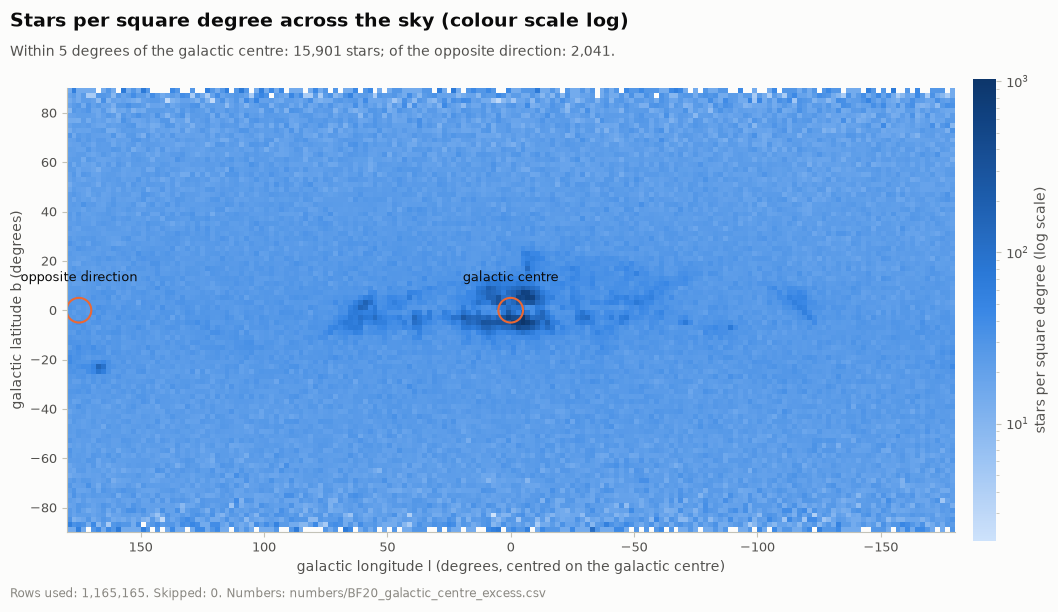

In [4]:
F = Facts(20, "galactic_centre_excess")
cl, cb_ = np.cos(np.radians(st["l"])), np.cos(np.radians(st["b"]))
gc = np.degrees(np.arccos(np.clip(cb_ * cl, -1, 1))) < 5
ac = np.degrees(np.arccos(np.clip(-cb_ * cl, -1, 1))) < 5
F.rule("radius", 5, "5", "degrees")
F.add("gc", int(gc.sum())); F.add("ac", int(ac.sum())); F.add("ratio", gc.sum() / ac.sum(), d(gc.sum() / ac.sum(), 1))
F.add("gc_ruwe", st.loc[gc, "ruwe"].median(), d(st.loc[gc, "ruwe"].median(), 2)); F.add("ac_ruwe", st.loc[ac, "ruwe"].median(), d(st.loc[ac, "ruwe"].median(), 2))
F.add("all_ruwe", st["ruwe"].median(), d(st["ruwe"].median(), 2))
F.add("gc_nocolour", 100 * st.loc[gc, "bp_rp"].isna().mean(), p(100 * st.loc[gc, "bp_rp"].isna().mean()))
F.add("all_nocolour", 100 * st["bp_rp"].isna().mean(), p(100 * st["bp_rp"].isna().mean()))
F.add("gc_ruwe_bad", 100 * (st.loc[gc, "ruwe"] > 1.4).mean(), p(100 * (st.loc[gc, "ruwe"] > 1.4).mean()))
F.add("all_ruwe_bad", 100 * (st["ruwe"] > 1.4).mean(), p(100 * (st["ruwe"] > 1.4).mean()))
lmc_l, lmc_b = 280.47, -32.89
def patch(l0, b0, r=5):
    c_ = np.sin(np.radians(st["b"])) * np.sin(np.radians(b0)) + cb_ * np.cos(np.radians(b0)) * np.cos(np.radians(st["l"] - l0))
    return np.degrees(np.arccos(np.clip(c_, -1, 1))) < r
F.outside("lmc_l", lmc_l, "280.5", "degrees", source="known science (Large Magellanic Cloud position)"); F.outside("lmc_b", lmc_b, "-32.9", "degrees", source="known science")
F.add("lmc", int(patch(lmc_l, lmc_b).sum())); F.add("lmc_mirror", int(patch(lmc_l, -lmc_b).sum()))
F.outside("guide_gc", 15895, "15,895", source="Field Guide"); F.outside("guide_ac", 2040, "2,040", source="Field Guide")
F.outside("guide_ruwe", 1.65, "1.65", source="Field Guide"); F.outside("guide_nocolour", 34, "34%", source="Field Guide")
F.outside("guide_lmc", 1594, "1,594", source="Field Guide"); F.outside("guide_lmc_mirror", 1587, "1,587", source="Field Guide")
print(F.table().to_string()); f20 = F.save()
lc = np.where(st["l"] > 180, st["l"] - 360, st["l"])
le, be = np.arange(-180, 181, 2), np.arange(-90, 91, 2)
Hs, _, _ = np.histogram2d(lc, st["b"], bins=[le, be])
area = 4 * np.cos(np.radians((be[:-1] + be[1:]) / 2))
dens = Hs / area[None, :]
fig, ax = plt.subplots(figsize=(12, 6))
cm2 = hp.seq_cmap(start_at_surface=False); cm2.set_bad(hp.SURFACE)
im = ax.pcolormesh(le, be, np.ma.masked_equal(dens.T, 0), cmap=cm2, norm=LogNorm(vmin=max(dens[dens > 0].min(), 1), vmax=dens.max()), rasterized=True)
for (x0, lab) in [(0, "galactic centre"), (180, "opposite direction")]:
    xs = x0 if x0 == 0 else 175
    ax.add_patch(plt.Circle((xs, 0), 5, fill=False, color=hp.SERIES[1], lw=1.5))
    ax.annotate(lab, (xs, 5), xytext=(0, 12), textcoords="offset points", ha="center", fontsize=9, color=hp.INK)
ax.set_xlim(180, -180); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("galactic longitude l (degrees, centred on the galactic centre)"); ax.set_ylabel("galactic latitude b (degrees)")
cbar = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cbar.set_label("stars per square degree (log scale)"); cbar.outline.set_visible(False)
hp.add_titles(fig, "Stars per square degree across the sky (colour scale log)",
              f"Within 5 degrees of the galactic centre: {int(gc.sum()):,} stars; of the opposite direction: {int(ac.sum()):,}.",
              hp.caption(N, 0, numbers_file="numbers/BF20_galactic_centre_excess.csv"))
c20 = hp.save_chart(fig, "BF20_sky_map"); plt.show()
hp.log_entry("E-BF20", "Beginner finding 20 chart: sky map per square degree", step=6, chart=c20, numbers=f20, rows_used=N, rows_skipped=0,
             key_numbers=[f"within 5 deg of the centre {int(gc.sum()):,}; opposite {int(ac.sum()):,}; median ruwe {st.loc[gc, 'ruwe'].median():.2f}"],
             what_it_shows="There is a strong pile of stars toward the galactic centre, with poor-fit measurements.")

## Finding 21: star clusters appear when you search position and motion together (DBSCAN)

               key          value    shown         unit                             source
0           sample  700570.000000  700,570                                        our data
1              eps       3.000000        3                                    rule we used
2      min_samples      12.000000       12                                    rule we used
3       vel_weight       4.000000        4                                    rule we used
4            g_cut      18.000000       18                                    rule we used
5           groups      24.000000       24                                        our data
6        in_groups    1964.000000    1,964                                        our data
7        top_stars     768.000000      768                                        our data
8           top_ra      56.648516     56.6      degrees                           our data
9          top_dec      24.115156     24.1      degrees                           our data

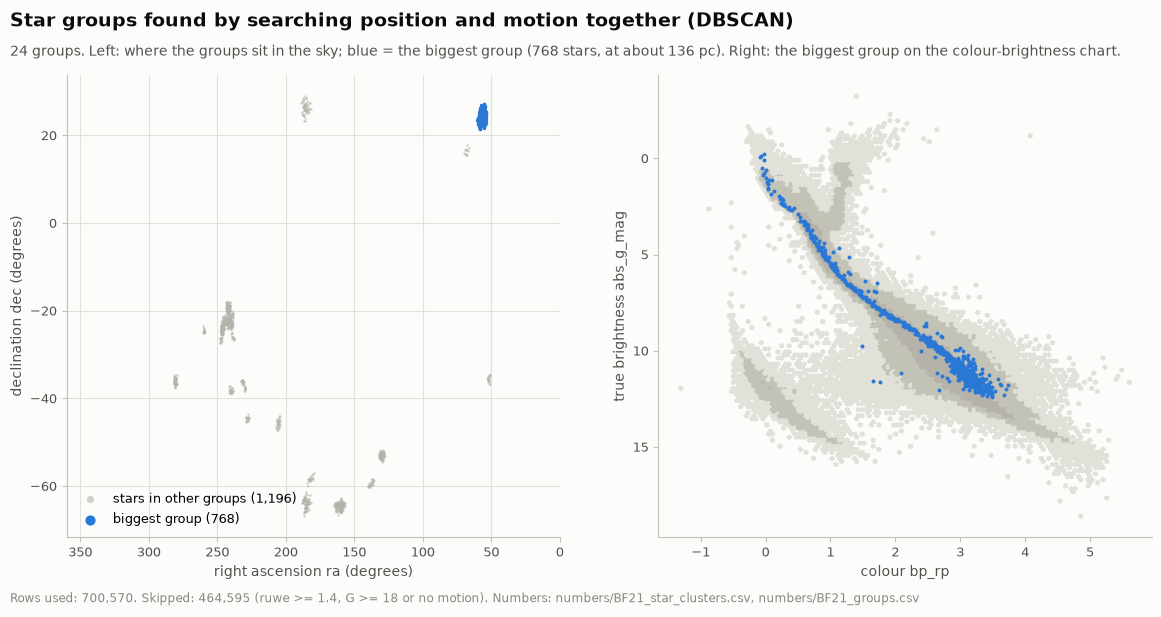

In [5]:
F = Facts(21, "star_clusters")
sel = (st["ruwe"] < 1.4) & (st["phot_g_mean_mag"] < 18) & st["pmra"].notna() & st["pmdec"].notna()
s21 = st.loc[sel].copy()
lr, br = np.radians(s21["l"]), np.radians(s21["b"])
s21["X"], s21["Y"], s21["Z"] = s21["distance_pc"] * np.cos(br) * np.cos(lr), s21["distance_pc"] * np.cos(br) * np.sin(lr), s21["distance_pc"] * np.sin(br)
s21["vra"], s21["vdec"] = s21["pmra"] * s21["distance_pc"] * 4.74 / 1000, s21["pmdec"] * s21["distance_pc"] * 4.74 / 1000
cache = hp.NUMBERS / "BF21_dbscan_labels.csv"
if cache.exists() and len(pd.read_csv(cache)) == len(s21):
    labels = pd.read_csv(cache)["label"].to_numpy()
else:
    hp.tick("DBSCAN start")
    Xf = np.column_stack([s21["X"], s21["Y"], s21["Z"], 4 * s21["vra"], 4 * s21["vdec"]])
    labels = DBSCAN(eps=3, min_samples=12, n_jobs=-1).fit_predict(Xf)
    hp.tick("DBSCAN done")
    pd.DataFrame({"source_id": s21["source_id"].astype(str).to_numpy(), "label": labels}).to_csv(cache, index=False)
s21["grp"] = labels
grp = s21[s21["grp"] >= 0].groupby("grp").agg(stars=("ra", "size"), ra=("ra", "median"), dec=("dec", "median"),
                                              distance_pc=("distance_pc", "median"), pmra=("pmra", "median"), pmdec=("pmdec", "median"))
grp = grp.sort_values("stars", ascending=False).reset_index()
grp.round(2).to_csv(hp.NUMBERS / "BF21_groups.csv", index=False)
F.add("sample", len(s21)); F.rule("eps", 3, "3"); F.rule("min_samples", 12, "12"); F.rule("vel_weight", 4, "4"); F.rule("g_cut", 18, "18")
F.add("groups", len(grp)); F.add("in_groups", int((labels >= 0).sum()))
top = grp.iloc[0]
F.add("top_stars", int(top["stars"])); F.add("top_ra", top["ra"], d(top["ra"], 1), "degrees"); F.add("top_dec", top["dec"], d(top["dec"], 1), "degrees")
F.add("top_dist", top["distance_pc"], n0(top["distance_pc"]), "pc"); F.add("top_ly", top["distance_pc"] * 3.26, n0(top["distance_pc"] * 3.26), "light-years")
F.add("top_pmra", top["pmra"], d(top["pmra"], 1), "mas/yr"); F.add("top_pmdec", top["pmdec"], d(top["pmdec"], 1), "mas/yr")
F.add("second_stars", int(grp.iloc[1]["stars"])); F.add("third_stars", int(grp.iloc[2]["stars"]))
F.outside("pleiades_ra", KNOWN["Pleiades (centre)"][0], "56.75", "degrees", source="known science (Pleiades position)")
F.outside("pleiades_dec", KNOWN["Pleiades (centre)"][1], "24.12", "degrees", source="known science (Pleiades position)")
F.outside("guide_groups", 24, "24", source="Field Guide"); F.outside("guide_top", 768, "768", source="Field Guide")
F.rule("km_s_factor", 4.74, "4.74")
F.rule("mas_per_arcsec", 1000, "1,000")
print(F.table().to_string()); print(grp.head(10).round(1).to_string()); f21 = F.save()
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
ingrp = s21[s21["grp"] >= 0]
axs[0].scatter(ingrp["ra"], ingrp["dec"], s=3, color=hp.GRAY, alpha=0.6, linewidths=0, label=f"stars in other groups ({len(ingrp) - int(top['stars']):,})")
t0 = s21[s21["grp"] == top["grp"]]
axs[0].scatter(t0["ra"], t0["dec"], s=6, color=hp.SERIES[0], linewidths=0, label=f"biggest group ({len(t0):,})")
axs[0].set_xlim(360, 0); axs[0].set_xlabel("right ascension ra (degrees)"); axs[0].set_ylabel("declination dec (degrees)"); axs[0].legend(loc="lower left", markerscale=3)
hb = has_col.loc[s21.index]
axs[1].hexbin(s21.loc[hb, "bp_rp"], s21.loc[hb, "abs_g_mag"], gridsize=120, bins="log", cmap=plt.matplotlib.colors.ListedColormap(["#e1e0d9", "#c3c2b7", "#b4b2a9"]), mincnt=1)
axs[1].scatter(t0["bp_rp"], t0["abs_g_mag"], s=8, color=hp.SERIES[0], linewidths=0)
axs[1].invert_yaxis(); axs[1].set_xlabel("colour bp_rp"); axs[1].set_ylabel("true brightness abs_g_mag"); axs[1].grid(False)
hp.add_titles(fig, "Star groups found by searching position and motion together (DBSCAN)",
              f"{len(grp)} groups. Left: where the groups sit in the sky; blue = the biggest group ({int(top['stars'])} stars, "
              f"at about {top['distance_pc']:.0f} pc). Right: the biggest group on the colour-brightness chart.",
              hp.caption(len(s21), N - len(s21), "ruwe >= 1.4, G >= 18 or no motion", "numbers/BF21_star_clusters.csv, numbers/BF21_groups.csv"))
c21 = hp.save_chart(fig, "BF21_star_groups"); plt.show()
hp.log_entry("E-BF21", "Beginner finding 21 chart: DBSCAN star groups", step=6, chart=c21, numbers=[f21, "numbers/BF21_groups.csv"],
             rows_used=len(s21), rows_skipped=f"{N - len(s21):,}", key_numbers=[f"{len(grp)} groups; biggest {int(top['stars'])} stars at {top['distance_pc']:.0f} pc"],
             what_it_shows="Stars that share position and motion form tight groups; the biggest sits at the Pleiades' position.")

## Finding 22: fast movers, and speeds that can't be right

                key          value             shown                 unit                                                              source
0            pm_max      10.393349              10.4  arcseconds per year                                                            our data
1       pm_max_dist       1.828234              1.83                   pc                                                            our data
2     barnard_match       0.000000               yes                                                                our data (position match)
3          groom_vt     307.004632               307                 km/s                                                            our data
4          groom_pm       7.061731              7.06            arcsec/yr                                                            our data
5        groom_dist       9.171818              9.17                   pc                                                            our data
6     

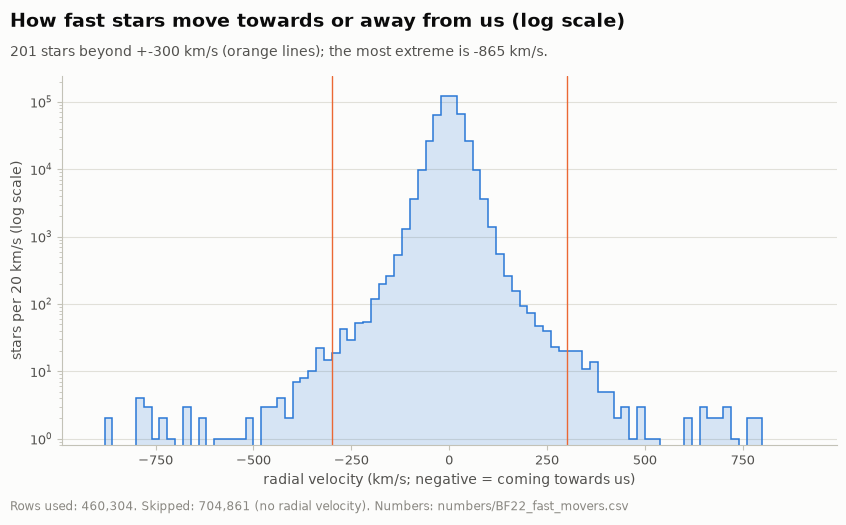

In [6]:
F = Facts(22, "fast_movers")
pm = np.hypot(st["pmra"], st["pmdec"])
vt = 4.74 * pm / 1000 * st["distance_pc"]
i_pm = pm.idxmax()
F.add("pm_max", pm[i_pm] / 1000, d(pm[i_pm] / 1000, 1), "arcseconds per year")
F.add("pm_max_dist", st.loc[i_pm, "distance_pc"], d(st.loc[i_pm, "distance_pc"], 2), "pc")
bn, dbn = nearest_to(*KNOWN["Barnard's Star"])
F.add("barnard_match", 0, "yes" if bn is not None and bn.name == i_pm else "no", source="our data (position match)")
gr, _ = nearest_to(*KNOWN["Groombridge 1830"])
F.add("groom_vt", vt[gr.name], n0(vt[gr.name]), "km/s"); F.add("groom_pm", pm[gr.name] / 1000, d(pm[gr.name] / 1000, 2), "arcsec/yr"); F.add("groom_dist", gr["distance_pc"], d(gr["distance_pc"], 2), "pc")
ka, _ = nearest_to(*KNOWN["Kapteyn's Star"])
F.add("kapteyn_rv", ka["radial_velocity"], n0(ka["radial_velocity"]), "km/s")
F.rule("vt_cut", 200, "200", "km/s"); F.add("vt_over_200", int((vt > 200).sum()))
rv = st["radial_velocity"]
F.rule("rv_cut", 300, "300", "km/s")
fastrv = rv.abs() > 300
F.add("rv_n", int(rv.notna().sum())); F.add("rv_over_300", int(fastrv.sum())); F.add("rv_over_300_pos", int((rv > 300).sum()))
F.add("rv_fast_g", st.loc[fastrv, "phot_g_mean_mag"].median(), d(st.loc[fastrv, "phot_g_mean_mag"].median(), 1))
F.add("rv_all_g", st.loc[rv.notna(), "phot_g_mean_mag"].median(), d(st.loc[rv.notna(), "phot_g_mean_mag"].median(), 1))
i_rv = rv.idxmin()
F.add("rv_min", rv[i_rv], n0(rv[i_rv]), "km/s"); F.add("rv_min_dist", st.loc[i_rv, "distance_pc"], n0(st.loc[i_rv, "distance_pc"]), "pc")
F.add("ex_pm_arcsec", pm[gr.name] / 1000, d(pm[gr.name] / 1000, 2))
F.add("ex_step1", 4.74 * pm[gr.name] / 1000, d(4.74 * pm[gr.name] / 1000, 2)); F.add("ex_step2", vt[gr.name], n0(vt[gr.name]))
F.outside("escape_speed", 550, "550", "km/s", source="known science (rough escape speed from the Milky Way near the Sun)")
F.add("groom_name", 0, "Groombridge 1830", source="known name, matched by position")
F.add("groom_rv", gr["radial_velocity"], d(gr["radial_velocity"], 1) if pd.notna(gr["radial_velocity"]) else "blank", "km/s")
F.add("groom_pmra", gr["pmra"], n0(gr["pmra"]), "mas/yr"); F.add("groom_pmdec", gr["pmdec"], n0(gr["pmdec"]), "mas/yr")
F.outside("guide_vt", 2280, "2,280", source="Field Guide")
print(F.table().to_string()); f22 = F.save()
fig, ax = plt.subplots(figsize=(10, 4.8))
edges = np.arange(-900, 901, 20)
cnt, _ = np.histogram(rv.dropna(), bins=edges)
hp.draw_hist(ax, cnt, edges)
ax.set_yscale("log"); ax.set_ylim(0.8, cnt.max() * 2)
for xv in (-300, 300):
    ax.axvline(xv, color=hp.SERIES[1], lw=1)
ax.set_xlabel("radial velocity (km/s; negative = coming towards us)"); ax.set_ylabel("stars per 20 km/s (log scale)"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "How fast stars move towards or away from us (log scale)",
              f"{int(fastrv.sum())} stars beyond +-300 km/s (orange lines); the most extreme is {rv[i_rv]:.0f} km/s.",
              hp.caption(int(rv.notna().sum()), N - int(rv.notna().sum()), "no radial velocity", "numbers/BF22_fast_movers.csv"))
c22 = hp.save_chart(fig, "BF22_radial_velocity"); plt.show()
hp.log_entry("E-BF22", "Beginner finding 22 chart: radial velocity histogram", step=6, chart=c22, numbers=f22, rows_used=int(rv.notna().sum()),
             rows_skipped=f"{N - int(rv.notna().sum()):,} (no radial velocity)",
             key_numbers=[f"|rv| > 300: {int(fastrv.sum())}; sideways > 200 km/s: {int((vt > 200).sum()):,}"],
             what_it_shows="A small number of stars have radial velocities beyond 300 km/s; most of them are faint.")
hp.edge_case("E", "Full Section E notebook not built (background builders stopped); beginner findings 18-22 were computed in notebooks/BF_E_stars.ipynb.")

## Plain version: "Meet the data" numbers and one plain chart per finding

Numbers for part E's "Meet the data" text: `numbers/BM_E_meet_stars.csv`. New plain charts `charts/K18_...png` to
`charts/K22_...png` (plotted numbers in `numbers/K18_...csv` ...), drawn with `simple_charts`.

In [7]:
kc.plain_style()
M = Meet("E", "meet_stars")
M.add("rows_total", N); M.add("n_columns", len(hp.columns("stars")))
M.add("count_days", N / 86400, d(N / 86400, 1), "days", source="our data (rows ÷ seconds in a day)")
M.add("max_pc", st["distance_pc"].max(), n0(st["distance_pc"].max()), "pc"); M.add("max_ly", st["distance_pc"].max() * 3.26, n0(st["distance_pc"].max() * 3.26), "light-years")
M.outside("pc_ly", 3.26, "3.26", "light-years", source="README (1 parsec)")
M.add("rv_have_pct", 100 * st["radial_velocity"].notna().mean(), p(100 * st["radial_velocity"].notna().mean()))
M.add("colour_blank_pct", 100 * st["bp_rp"].isna().mean(), p(100 * st["bp_rp"].isna().mean()))
M.add("ruwe_bad_pct", 100 * (st["ruwe"] > 1.4).mean(), p(100 * (st["ruwe"] > 1.4).mean())); M.rule("ruwe_cut", 1.4, "1.4")
M.add("median_ly", st["distance_pc"].median() * 3.26, n0(st["distance_pc"].median() * 3.26), "light-years")
M.outside("eye_limit", 6, "6", source="known science (faintest stars an eye can see on a dark night: brightness number about 6)")
M.outside("coin_km", 4, "4", "km", source="known science (a coin about 2 cm wide seen from about 4 km covers about one arcsecond)")
M.add("eye_visible", int((st["phot_g_mean_mag"] <= 6).sum()))
pr = px
for col_, key_, k_ in [("ra", "ra", 2), ("dec", "dec", 2), ("l", "l", 1), ("b", "b", 1), ("distance_pc", "dist", 2), ("pmra", "pmra", 0),
                       ("pmdec", "pmdec", 0), ("phot_g_mean_mag", "g", 2), ("bp_rp", "bp_rp", 2), ("abs_g_mag", "absg", 2), ("ruwe", "ruwe", 2)]:
    M.add(f"prox_{key_}", pr[col_], d(pr[col_], k_) if k_ else n0(pr[col_]))
M.add("prox_rv", pr["radial_velocity"], d(pr["radial_velocity"], 1) if pd.notna(pr["radial_velocity"]) else "blank", "km/s")
M.add("prox_ly", pr["distance_pc"] * 3.26, d(pr["distance_pc"] * 3.26, 2), "light-years")
M.add("prox_id", 0, str(st.at[px.name, "source_id"]), source="our data (Gaia ID, read from the whole-number column)")
M.add("prox_pm_arcsec", np.hypot(pr["pmra"], pr["pmdec"]) / 1000, d(np.hypot(pr["pmra"], pr["pmdec"]) / 1000, 2), "arcseconds per year")
M.rule("mas_per_arcsec", 1000, "1,000")
print(M.table().to_string()); fmE = M.save()

                 key         value                shown                 unit                                                                                    source
0         rows_total  1.165165e+06            1,165,165                                                                                                       our data
1          n_columns  2.100000e+01                   21                                                                                                       our data
2         count_days  1.348571e+01                 13.5                 days                                                        our data (rows ÷ seconds in a day)
3             max_pc  1.538461e+02                  154                   pc                                                                                  our data
4             max_ly  5.015381e+02                  502          light-years                                                                                  our dat

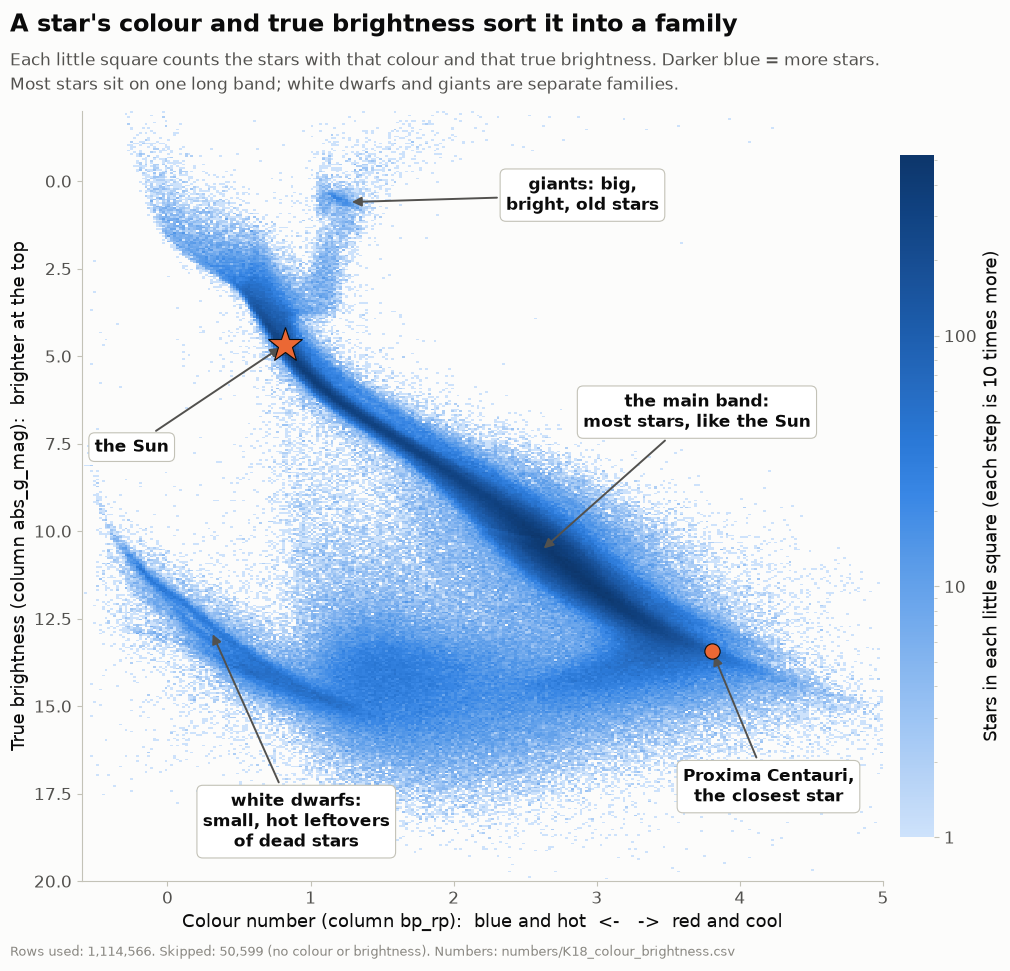

In [8]:
# K18: colour against true brightness, with plain labels
fig, ax = plt.subplots(figsize=(11, 10))
im = ax.pcolormesh(xe, ye, np.ma.masked_equal(H2.T, 0), cmap=cm, norm=LogNorm(vmin=1, vmax=H2.max()), rasterized=True)
ax.invert_yaxis(); ax.grid(False)
ax.plot(0.82, 4.67, marker="*", ms=26, color=kc.HIGHLIGHT, mec=hp.INK, mew=0.8, zorder=11)
kc.point_at(ax, (0.82, 4.67), "the Sun", (-0.25, 7.6))
ax.plot(px["bp_rp"], px["abs_g_mag"], marker="o", ms=11, color=kc.HIGHLIGHT, mec=hp.INK, mew=0.8, zorder=11)
kc.point_at(ax, (px["bp_rp"], px["abs_g_mag"]), "Proxima Centauri,\nthe closest star", (4.2, 17.3))
kc.point_at(ax, (2.6, 10.6), "the main band:\nmost stars, like the Sun", (3.7, 6.6))
kc.point_at(ax, (0.3, 12.8), "white dwarfs:\nsmall, hot leftovers\nof dead stars", (0.9, 18.3))
kc.point_at(ax, (1.25, 0.6), "giants: big,\nbright, old stars", (2.9, 0.4))
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.outline.set_visible(False)
cb.set_label("Stars in each little square (each step is 10 times more)")
tk_ = [t_ for t_ in [1, 10, 100, 1000] if t_ <= H2.max()]; cb.set_ticks(tk_); cb.set_ticklabels([f"{t_:,}" for t_ in tk_])
ax.set_xlabel("Colour number (column bp_rp):  blue and hot  <-   ->  red and cool")
ax.set_ylabel("True brightness (column abs_g_mag):  brighter at the top")
kc.titles(fig, "A star's colour and true brightness sort it into a family",
          "Each little square counts the stars with that colour and that true brightness. Darker blue = more stars. "
          "Most stars sit on one long band; white dwarfs and giants are separate families.",
          hp.caption(int(has_col.sum()), N - int(has_col.sum()), "no colour or brightness", "numbers/K18_colour_brightness.csv"))
n18 = hp.save_numbers(pd.DataFrame({"family": ["main band", "white dwarf-like", "giant-like"],
                                    "stars": [int(ms.sum()), int(wd.sum()), int(giant.sum())]}), "K18_colour_brightness")
c18_ = kc.save(fig, "K18_colour_brightness"); plt.show()
hp.log_entry("E-K18", "Simple chart for finding 18: colour against true brightness", step=6, chart=c18_, numbers=n18,
             rows_used=int(has_col.sum()), key_numbers=[f"main band {int(ms.sum()):,}; white dwarf-like {int(wd.sum()):,}; giant-like {int(giant.sum()):,}"],
             what_it_shows="Stars fall into a main band, a white-dwarf band and a small giant clump.")

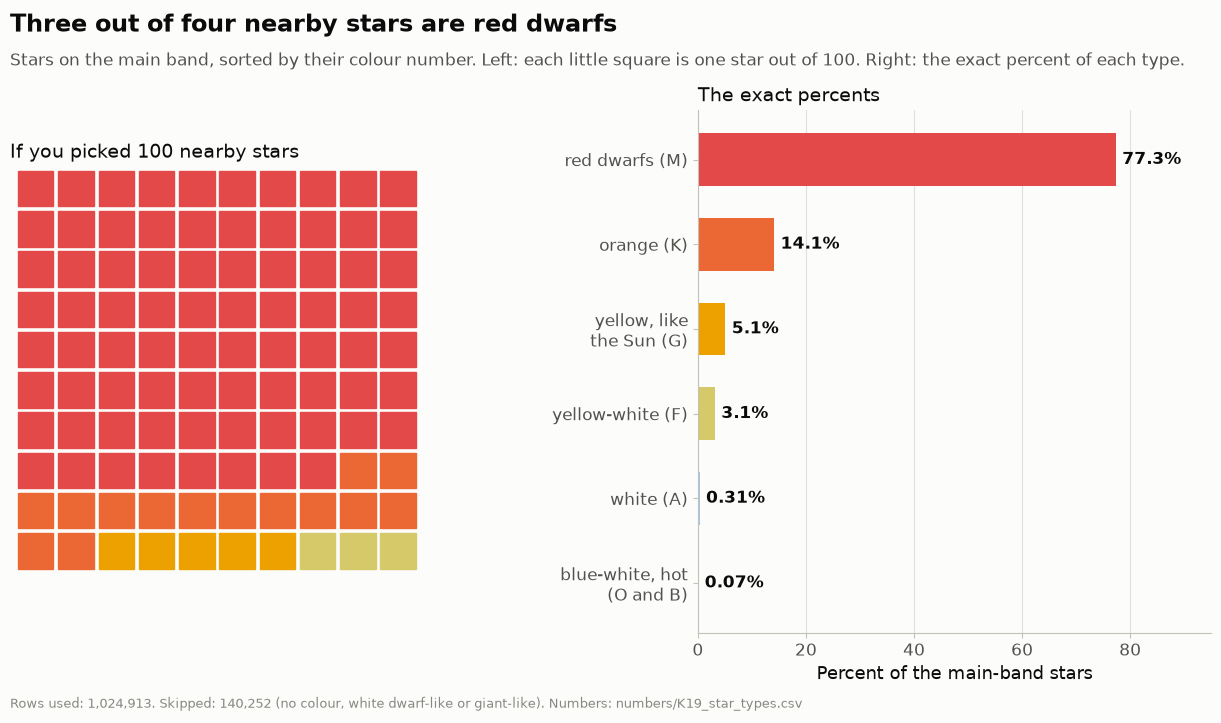

In [9]:
# K19: if you picked 100 nearby stars (left) and the exact percents (right)
KCOL = {"M": "#e34948", "K": "#eb6834", "G": "#eda100", "F": "#d6c96a", "A": "#9ec5f4", "O/B": "#2a78d6"}
KNAME = {"M": "red dwarfs (M)", "K": "orange (K)", "G": "yellow, like\nthe Sun (G)", "F": "yellow-white (F)", "A": "white (A)",
         "O/B": "blue-white, hot\n(O and B)"}
order = ["M", "K", "G", "F", "A", "O/B"]
boxes = [nm for nm in order for _ in range(int(w100[nm]))]
t19 = pd.DataFrame({"type": order, "stars": [int(cls[nm]) for nm in order], "percent": [round(100 * cls[nm] / cls.sum(), 2) for nm in order],
                    "out_of_100": [int(w100[nm]) for nm in order]})
n19 = hp.save_numbers(t19, "K19_star_types")
fig, (axW, axB) = plt.subplots(1, 2, figsize=(15.5, 6.8), gridspec_kw={"width_ratios": [1, 1.25], "wspace": 0.6})
for k_, nm in enumerate(boxes):
    r_, c_ = divmod(k_, 10)
    axW.add_patch(plt.Rectangle((c_, 9 - r_), 0.88, 0.88, color=KCOL[nm]))
axW.set_xlim(-0.2, 10); axW.set_ylim(-0.2, 10); axW.set_aspect("equal"); axW.axis("off")
axW.set_title("If you picked 100 nearby stars", fontsize=13.5, color=hp.INK, loc="left")
yy19 = np.arange(len(order))[::-1]
pct19 = t19["percent"].to_numpy()
axB.barh(yy19, pct19, height=0.62, color=[KCOL[nm] for nm in order])
for y_, v_, nm in zip(yy19, pct19, order):
    kc.label(axB, v_ + 1.2, y_, f"{v_:.2f}%" if v_ < 1 else f"{v_:.1f}%", va="center", fontsize=12, bold=True)
axB.set_yticks(yy19, [KNAME[nm] for nm in order]); axB.set_xlim(0, 95); axB.grid(axis="y", visible=False)
axB.set_xlabel("Percent of the main-band stars")
axB.set_title("The exact percents", fontsize=13.5, color=hp.INK, loc="left")
kc.titles(fig, "Three out of four nearby stars are red dwarfs",
          "Stars on the main band, sorted by their colour number. Left: each little square is one star out of 100. "
          "Right: the exact percent of each type.",
          hp.caption(int(ms.sum()), N - int(ms.sum()), "no colour, white dwarf-like or giant-like", n19))
c19_ = kc.save(fig, "K19_star_types"); plt.show()
hp.log_entry("E-K19", "Simple chart for finding 19: 100 nearby stars and star types", step=6, chart=c19_, numbers=n19,
             rows_used=int(ms.sum()), key_numbers=[f"out of 100: M {int(w100['M'])}, K {int(w100['K'])}, G {int(w100['G'])}"],
             what_it_shows="Red dwarfs fill about three quarters of the 100 squares.")

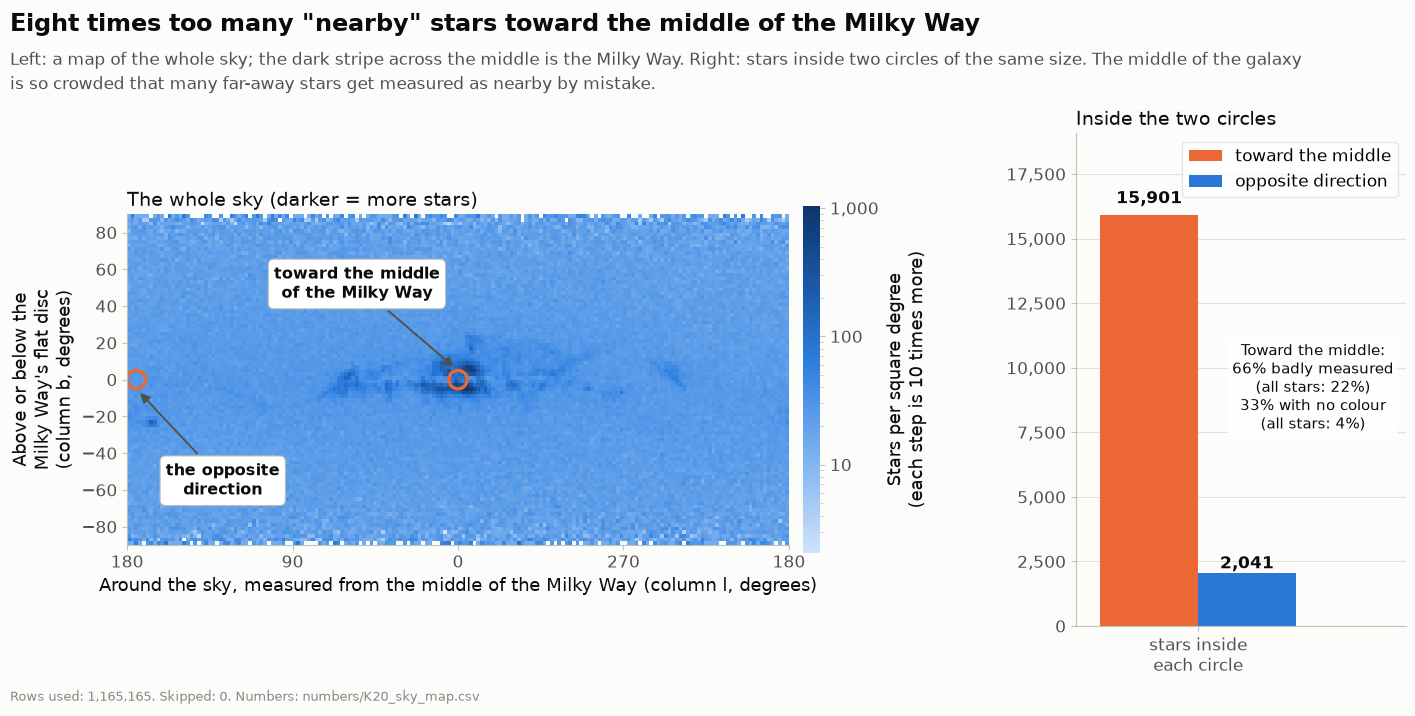

In [10]:
# K20: sky map (left) and the two circles compared (right)
fig, (axS, axC) = plt.subplots(1, 2, figsize=(16.5, 6.4), gridspec_kw={"width_ratios": [2.1, 1], "wspace": 0.5})
im = axS.pcolormesh(le, be, np.ma.masked_equal(dens.T, 0), cmap=cm2, norm=LogNorm(vmin=max(dens[dens > 0].min(), 1), vmax=dens.max()), rasterized=True)
for xs, lab, xyt in [(0, "toward the middle\nof the Milky Way", (55, 52)), (175, "the opposite\ndirection", (128, -55))]:
    axS.add_patch(plt.Circle((xs, 0), 5, fill=False, color=kc.HIGHLIGHT, lw=2.4))
    kc.point_at(axS, (xs, 5 if xs == 0 else -5), lab, xyt, fontsize=11.5)
axS.set_xlim(180, -180); axS.set_ylim(-90, 90); axS.set_aspect("equal"); axS.grid(False)
axS.set_xticks([180, 90, 0, -90, -180], ["180", "90", "0", "270", "180"])
axS.set_xlabel("Around the sky, measured from the middle of the Milky Way (column l, degrees)")
axS.set_ylabel("Above or below the\nMilky Way's flat disc\n(column b, degrees)")
cbar = fig.colorbar(im, ax=axS, fraction=0.025, pad=0.02); cbar.outline.set_visible(False)
cbar.set_label("Stars per square degree\n(each step is 10 times more)")
tk2 = [t_ for t_ in [1, 10, 100, 1000, 10000] if dens[dens > 0].min() <= t_ <= dens.max()]; cbar.set_ticks(tk2); cbar.set_ticklabels([f"{t_:,}" for t_ in tk2])
axS.set_title("The whole sky (darker = more stars)", fontsize=13.5, color=hp.INK, loc="left")
labs = ["stars counted", "wobble score\nover 1.4 (%)", "no colour (%)"]
gc_v = [int(gc.sum()), 100 * (st.loc[gc, "ruwe"] > 1.4).mean(), 100 * st.loc[gc, "bp_rp"].isna().mean()]
ac_v = [int(ac.sum()), 100 * (st.loc[ac, "ruwe"] > 1.4).mean(), 100 * st.loc[ac, "bp_rp"].isna().mean()]
t20 = pd.DataFrame({"measure": ["stars counted", "wobble score over 1.4 (%)", "no colour (%)"], "toward_middle": np.round(gc_v, 1),
                    "opposite_direction": np.round(ac_v, 1)})
n20 = hp.save_numbers(t20, "K20_sky_map")
axC.bar([0 - 0.2], [gc_v[0]], width=0.4, color=kc.HIGHLIGHT, label="toward the middle")
axC.bar([0 + 0.2], [ac_v[0]], width=0.4, color=kc.MAIN, label="opposite direction")
kc.label(axC, -0.2, gc_v[0] * 1.02, n0(gc_v[0]), ha="center", va="bottom", bold=True)
kc.label(axC, 0.2, ac_v[0] * 1.02, n0(ac_v[0]), ha="center", va="bottom", bold=True)
axC.set_xticks([0], ["stars inside\neach circle"]); axC.set_ylim(0, gc_v[0] * 1.2); axC.set_xlim(-0.5, 0.85); kc.plain_axis(axC, "y")
axC.legend(loc="upper right", frameon=True, facecolor="white", edgecolor=hp.GRID)
axC.grid(axis="x", visible=False)
axC.set_title("Inside the two circles", fontsize=13.5, color=hp.INK, loc="left")
kc.label(axC, 0.47, gc_v[0] * 0.58, f"Toward the middle:\n{p(gc_v[1])} badly measured\n(all stars: {p(100 * (st['ruwe'] > 1.4).mean())})\n"
         f"{p(gc_v[2])} with no colour\n(all stars: {p(100 * st['bp_rp'].isna().mean())})", ha="center", va="center", fontsize=11, box=True)
kc.titles(fig, "Eight times too many \"nearby\" stars toward the middle of the Milky Way",
          "Left: a map of the whole sky; the dark stripe across the middle is the Milky Way. Right: stars inside two circles of the same size. "
          "The middle of the galaxy is so crowded that many far-away stars get measured as nearby by mistake.",
          hp.caption(N, 0, "", n20))
c20_ = kc.save(fig, "K20_sky_map"); plt.show()
hp.log_entry("E-K20", "Simple chart for finding 20: sky map and the two circles", step=6, chart=c20_, numbers=n20, rows_used=N,
             key_numbers=[f"toward the middle {int(gc.sum()):,}; opposite {int(ac.sum()):,}"],
             what_it_shows="The circle toward the galaxy's middle holds about 8 times as many stars, many badly measured.")

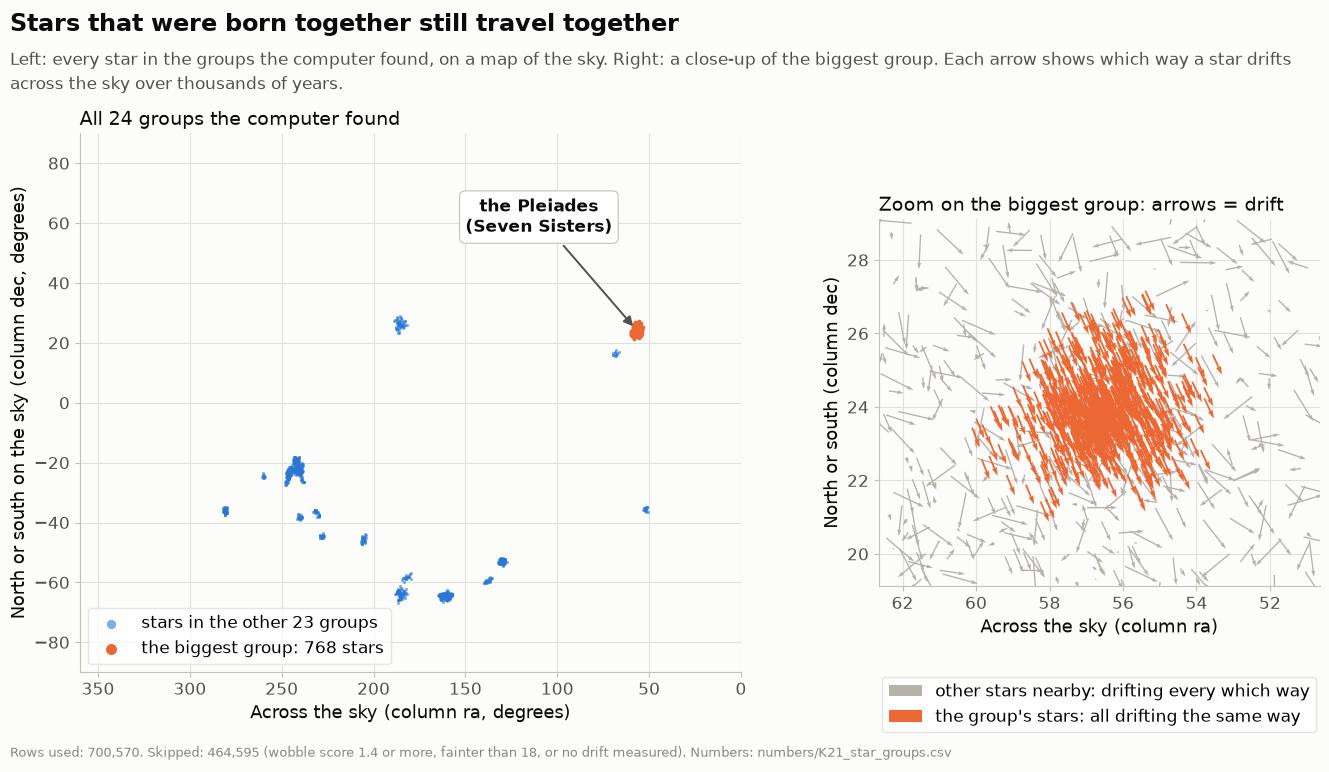

In [11]:
# K21: groups of stars that sit together and move together: sky map (left), the biggest group's motion (right)
fig, (axL, axR) = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.25})
other = ingrp[ingrp["grp"] != top["grp"]]
axL.scatter(other["ra"], other["dec"], s=5, color=kc.MAIN, alpha=0.6, linewidths=0, label=f"stars in the other {len(grp) - 1} groups")
axL.scatter(t0["ra"], t0["dec"], s=7, color=kc.HIGHLIGHT, linewidths=0, label=f"the biggest group: {len(t0):,} stars")
kc.point_at(axL, (top["ra"], top["dec"]), "the Pleiades\n(Seven Sisters)", (110, 62))
axL.set_xlim(360, 0); axL.set_ylim(-90, 90)
axL.set_xlabel("Across the sky (column ra, degrees)"); axL.set_ylabel("North or south on the sky (column dec, degrees)")
axL.legend(loc="lower left", markerscale=3, frameon=True, facecolor="white", edgecolor=hp.GRID)
axL.set_title(f"All {len(grp)} groups the computer found", fontsize=13.5, color=hp.INK, loc="left")
box = (s21["ra"].between(top["ra"] - 6, top["ra"] + 6)) & (s21["dec"].between(top["dec"] - 5, top["dec"] + 5))
fld = s21[box & (s21["grp"] != top["grp"])].sample(n=min(400, int((box & (s21["grp"] != top["grp"])).sum())), random_state=1)
mem = t0[(t0["ra"].between(top["ra"] - 6, top["ra"] + 6)) & (t0["dec"].between(top["dec"] - 5, top["dec"] + 5))]
sc = 0.012
len_f = np.hypot(fld["pmra"], fld["pmdec"]) * sc; cut_f = np.minimum(1, 1.0 / len_f)   # long arrows trimmed to 1 degree, same direction
axR.quiver(fld["ra"], fld["dec"], -fld["pmra"] * sc * cut_f, fld["pmdec"] * sc * cut_f, angles="xy", scale_units="xy", scale=1, color=hp.GRAY,
           width=0.003, label="other stars nearby: drifting every which way")
axR.quiver(mem["ra"], mem["dec"], -mem["pmra"] * sc, mem["pmdec"] * sc, angles="xy", scale_units="xy", scale=1, color=kc.HIGHLIGHT,
           width=0.004, label="the group's stars: all drifting the same way")
axR.set_xlim(top["ra"] + 6, top["ra"] - 6); axR.set_ylim(top["dec"] - 5, top["dec"] + 5); axR.set_aspect("equal")
axR.set_xlabel("Across the sky (column ra)"); axR.set_ylabel("North or south (column dec)")
axR.legend(loc="lower center", bbox_to_anchor=(0.5, -0.42), frameon=True, facecolor="white", edgecolor=hp.GRID)
axR.set_title("Zoom on the biggest group: arrows = drift", fontsize=13.5, color=hp.INK, loc="left")
t21 = grp.head(10).round(2)
n21 = hp.save_numbers(t21, "K21_star_groups")
kc.titles(fig, "Stars that were born together still travel together",
          "Left: every star in the groups the computer found, on a map of the sky. Right: a close-up of the biggest group. "
          "Each arrow shows which way a star drifts across the sky over thousands of years.",
          hp.caption(len(s21), N - len(s21), "wobble score 1.4 or more, fainter than 18, or no drift measured", n21))
c21_ = kc.save(fig, "K21_star_groups"); plt.show()
hp.log_entry("E-K21", "Simple chart for finding 21: star groups and the Pleiades' shared drift", step=6, chart=c21_, numbers=n21,
             rows_used=len(s21), key_numbers=[f"{len(grp)} groups; biggest {int(top['stars'])} stars"],
             what_it_shows="Group members drift together (orange arrows) while nearby field stars drift in all directions.")

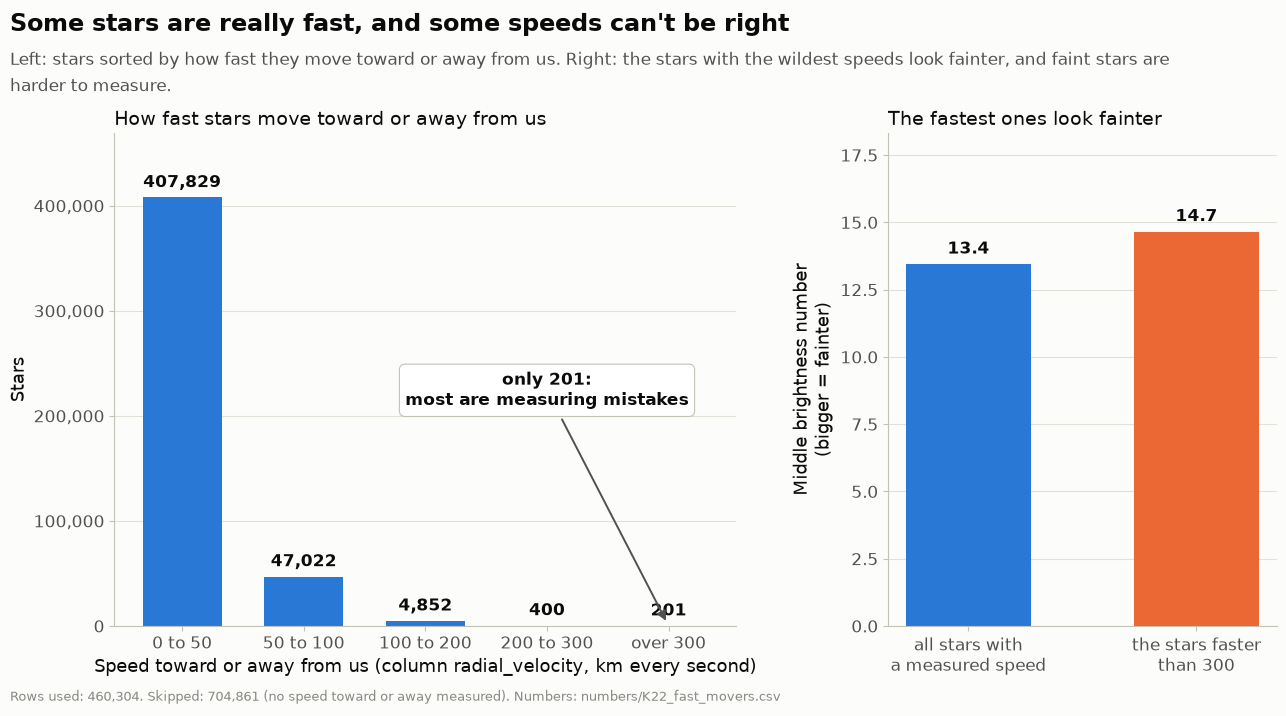

In [12]:
# K22: speeds toward or away from us, in bands (left), and how bright the fast ones look (right)
bands = [(0, 50), (50, 100), (100, 200), (200, 300), (300, np.inf)]
rva = rv.abs().dropna()
cnt22 = [int(((rva >= lo) & (rva < hi)).sum()) for lo, hi in bands]
lab22 = ["0 to 50", "50 to 100", "100 to 200", "200 to 300", "over 300"]
t22 = pd.DataFrame({"speed_band_km_s": lab22, "stars": cnt22})
n22 = hp.save_numbers(t22, "K22_fast_movers")
fig, (axL, axR) = plt.subplots(1, 2, figsize=(15, 6.4), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.3})
axL.bar(range(5), cnt22, color=[kc.HIGHLIGHT if k_ == 4 else kc.MAIN for k_ in range(5)], width=0.65)
for k_, v_ in enumerate(cnt22):
    kc.label(axL, k_, v_ + max(cnt22) * 0.015, n0(v_), ha="center", va="bottom", bold=True)
axL.set_xticks(range(5), lab22); axL.set_ylim(0, max(cnt22) * 1.15); kc.plain_axis(axL, "y"); axL.grid(axis="x", visible=False)
axL.set_xlabel("Speed toward or away from us (column radial_velocity, km every second)")
axL.set_ylabel("Stars")
kc.point_at(axL, (4, cnt22[4]), f"only {n0(cnt22[4])}:\nmost are measuring mistakes", (3.0, max(cnt22) * 0.55))
axL.set_title("How fast stars move toward or away from us", fontsize=13.5, color=hp.INK, loc="left")
gv = [st.loc[rv.notna(), "phot_g_mean_mag"].median(), st.loc[fastrv, "phot_g_mean_mag"].median()]
axR.bar([0, 1], gv, color=[kc.MAIN, kc.HIGHLIGHT], width=0.55)
for k_, v_ in enumerate(gv):
    kc.label(axR, k_, v_ + 0.25, d(v_, 1), ha="center", va="bottom", bold=True)
axR.set_xticks([0, 1], ["all stars with\na measured speed", "the stars faster\nthan 300"]); axR.set_ylim(0, max(gv) * 1.25)
axR.set_ylabel("Middle brightness number\n(bigger = fainter)"); axR.grid(axis="x", visible=False)
axR.set_title("The fastest ones look fainter", fontsize=13.5, color=hp.INK, loc="left")
kc.titles(fig, "Some stars are really fast, and some speeds can't be right",
          "Left: stars sorted by how fast they move toward or away from us. Right: the stars with the wildest speeds look "
          "fainter, and faint stars are harder to measure.",
          hp.caption(int(rv.notna().sum()), N - int(rv.notna().sum()), "no speed toward or away measured", n22))
c22_ = kc.save(fig, "K22_fast_movers"); plt.show()
hp.log_entry("E-K22", "Simple chart for finding 22: speed bands and brightness of the fastest", step=6, chart=c22_, numbers=n22,
             rows_used=int(rv.notna().sum()), key_numbers=[f"over 300 km/s: {cnt22[4]}"],
             what_it_shows="Almost all stars move under 100 km/s; the 201 over 300 km/s look fainter.")